# Bab 10 — Neural learning about edges and corners: intro to convolutional neural networks

**Mahasiswa:** Tarannia Raisha Putri · 101032300231 · TK4702 · Deep Learning

**Referensi utama:** Andrew W. Trask, *Grokking Deep Learning*, Manning (2019), Bab 10, halaman cetak 177–185 (PDF 198–206, indeks PDF mulai 1). Subbab spesifik dicantumkan pada setiap tahap.

**Tujuan pembelajaran:** Mengimplementasikan patch extraction, parameter sharing, forward/backward kernel, dan mengaudit batas jendela.

## Ringkasan

CNN memakai sekumpulan bobot yang sama pada banyak lokasi gambar. Buku membangun operasi ini sebagai ekstraksi patch dan perkalian matriks, dilanjutkan tanh, dropout, dan classifier MNIST.

## Konsep, intuisi, dan notasi

Untuk gambar $(B,28,28)$ dan kernel 3×3 dengan 16 kanal keluaran, patch berukuran 9. Valid convolution standar stride 1 memiliki $P=(28-3+1)^2=676$ lokasi. Listing buku memakai $P=(28-3)^2=625$, sehingga tepi akhir terlewat.

$A\in\mathbb R^{BP\times9}$ berisi patch, $K\in\mathbb R^{9\times16}$ bobot bersama, $Z=AK$. Hasil direshape menjadi $(B,16P)$ lalu $U\in\mathbb R^{16P\times10}$. Gradien kernel $G_K=A^TD_Z$ menjumlahkan kontribusi semua posisi karena parameter yang sama dipakai berulang. Operasi tanpa membalik kernel secara teknis adalah cross-correlation, istilah yang sering disebut convolution dalam jaringan saraf.

Convolution mengurangi parameter lokal dibanding dense image→hidden, tetapi classifier flatten masih besar. Pergeseran input menggeser feature map pada interior; flatten+dense tidak otomatis membuat prediksi sepenuhnya invariant terhadap translasi. Buku ini belum menambahkan pooling.

## Persiapan dan cara membaca

Jalankan **Restart Kernel → Run All**. Semua penjelasan merupakan parafrasa orisinal; angka hasil berada pada output sel yang benar-benar dijalankan. Label **reproduksi** berarti algoritme/contoh buku ditulis ulang; **koreksi/penyesuaian** menunjukkan perubahan; **tambahan** menunjukkan eksperimen atau interpretasi praktikum. `GDL_MODE=quick` mengurangi latihan berat; `full` memilih anggaran buku, dengan perubahan yang tetap dicatat. Keberhasilan eksekusi tidak membuktikan kesamaan akurasi dengan buku.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Jalankan dari root repository atau notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
MODE = os.environ.get('GDL_MODE', 'quick')
assert MODE in {'quick', 'full'}
FULL = MODE == 'full'
np.random.seed(1)
np.set_printoptions(precision=6, suppress=True)
METRICS = {}
def record(**values):
    METRICS.update(values)
def finite(*arrays):
    assert all(np.isfinite(np.asarray(a)).all() for a in arrays), 'NaN/inf terdeteksi'
def softmax(z):
    z = np.asarray(z)
    e = np.exp(z - np.max(z, axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)
def sigmoid(z):
    return np.exp(-np.logaddexp(0, -np.asarray(z)))
print('Mode:', MODE, '| NumPy:', np.__version__)

Mode: quick | NumPy: 2.5.4


<a id="b10-patch"></a>

## Reproduksi: weight sharing dan convolutional layer

**Sumber:** cetak 178–181; PDF 199–202.

Dua batas patch tersedia: `book=True` mempertahankan 25×25, `False` menghasilkan 26×26. Fungsi `get_image_section` memperbaiki ketidakkonsistenan nama `sub_section/subsection` pada cetak. Tiap patch memakai K yang sama.

In [2]:
def get_image_section(layer,r0,r1,c0,c1):
    section=layer[:,r0:r1,c0:c1]
    return section.reshape(len(layer),1,r1-r0,c1-c0)
def patches(images,k=3,book=False):
    end_r=images.shape[1]-k+(0 if book else 1)
    end_c=images.shape[2]-k+(0 if book else 1)
    sections=[get_image_section(images,r,r+k,c,c+k) for r in range(end_r) for c in range(end_c)]
    expanded=np.concatenate(sections,axis=1)
    return expanded.reshape(len(images),end_r*end_c,k*k)
from src.datasets import mnist
x_train,y_train,x_test,y_test=mnist()
print('Patch listing:',patches(x_train[:2],book=True).shape)
print('Patch valid lengkap:',patches(x_train[:2]).shape)
np.testing.assert_array_equal(patches(x_train[:1])[0,0],x_train[0,:3,:3].ravel())

Patch listing: (2, 625, 9)
Patch valid lengkap: (2, 676, 9)


<a id="b10-cnn"></a>

## Reproduksi NumPy dan koreksi gradien

**Sumber:** cetak 182–185; PDF 203–206.

Listing cetak menggunakan delta target−prediksi lalu menambah update classifier tetapi mengurangi update kernel. Ini memberi arah berlawanan pada dua matriks. Cabang `book=True` mempertahankannya untuk observasi. Koreksi memakai delta prediksi−target dan mengurangi kedua gradien.

Koreksi juga memakai tanh sebelum dropout, scaling masker 2, pembagian batch sekali, dan batch terakhir yang lebih kecil. **Mode ringan:** 256 train/200 test, 4 epoch; **penuh:** 1.000 train/10.000 test, 300 epoch, kernel 3×3×16, batch 128. Alpha koreksi=2/128 untuk menyamakan skala dasar dengan pembagi B² pada buku. Bukan klaim hasil identik.

listing epoch 1 [CE,train acc,test acc] [np.float64(2.3220979297030206), np.float64(0.046875), np.float64(0.095)]
listing epoch 2 [CE,train acc,test acc] [np.float64(2.339294694132026), np.float64(0.0390625), np.float64(0.075)]


listing epoch 3 [CE,train acc,test acc] [np.float64(2.3579046805483053), np.float64(0.02734375), np.float64(0.07)]
listing epoch 4 [CE,train acc,test acc] [np.float64(2.3754077196648176), np.float64(0.01953125), np.float64(0.07)]


koreksi epoch 1 [CE,train acc,test acc] [np.float64(2.2779739208851657), np.float64(0.19140625), np.float64(0.165)]
koreksi epoch 2 [CE,train acc,test acc] [np.float64(2.259246905534483), np.float64(0.26171875), np.float64(0.195)]


koreksi epoch 3 [CE,train acc,test acc] [np.float64(2.2424735311140256), np.float64(0.26953125), np.float64(0.2)]
koreksi epoch 4 [CE,train acc,test acc] [np.float64(2.2240270460812503), np.float64(0.26171875), np.float64(0.195)]


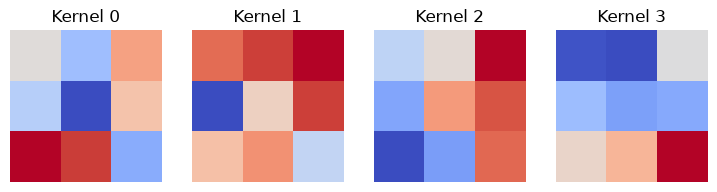

Kernel yang ditampilkan adalah bobot aktual; pola yang tampak belum membuktikan detektor tepi matang.


In [3]:
def train_cnn(book=False):
    rng=np.random.RandomState(1); N=1000 if FULL else 256; T=10000 if FULL else 200
    X=x_train[:N].astype(float)/255; Y=np.eye(10)[y_train[:N]]
    Xt=x_test[:T].astype(float)/255; Yt=y_test[:T]
    A=patches(X,book=book); At=patches(Xt,book=book)
    P=A.shape[1]; K=.02*rng.rand(9,16)-.01; U=.2*rng.rand(P*16,10)-.1
    log=[]; epochs=300 if FULL else 4; alpha=2. if book else 2/128
    def predict(A):
        h=np.tanh(A.reshape(-1,9)@K).reshape(len(A),-1)
        return softmax(h@U)
    for epoch in range(epochs):
        stop=(N//128)*128 if book else N
        for start in range(0,stop,128):
            Xb=A[start:start+128]; Yb=Y[start:start+128]; B=len(Xb)
            flat=Xb.reshape(-1,9); Z=flat@K; H=np.tanh(Z).reshape(B,-1)
            mask=rng.randint(2,size=H.shape); Hd=H*mask*2; prob=softmax(Hd@U)
            d2=(prob-Yb)/(B*B if book else B)
            d1=(d2@U.T)*(1-Hd**2 if book else 1-H**2)*mask*(1 if book else 2)
            GU=Hd.T@d2; GK=flat.T@d1.reshape(-1,16)
            U-=alpha*GU
            K+=alpha*GK if book else -alpha*GK
        prob=predict(A); test_prob=predict(At)
        ce=-np.sum(Y*np.log(np.maximum(prob,1e-300)))/N
        log.append([ce,np.mean(prob.argmax(1)==Y.argmax(1)),np.mean(test_prob.argmax(1)==Yt)])
        print('listing' if book else 'koreksi','epoch',epoch+1,'[CE,train acc,test acc]',log[-1])
    finite(K,U,log)
    return K,U,np.array(log)
cnn_book=train_cnn(True); cnn_fixed=train_cnn(False)
fig,axes=plt.subplots(1,4,figsize=(9,2))
for j,ax in enumerate(axes):
    ax.imshow(cnn_fixed[0][:,j].reshape(3,3),cmap='coolwarm'); ax.set_title(f'Kernel {j}'); ax.axis('off')
plt.show()
print('Kernel yang ditampilkan adalah bobot aktual; pola yang tampak belum membuktikan detektor tepi matang.')

<a id="b10-gradient"></a>

## Tambahan: uji kernel dan pembagian bobot

**Sumber:** cetak 183–183; PDF 204–204.

Central difference menggunakan citra kecil deterministik, tanpa dropout, dan seluruh komponen loss. Ini dataset tambahan untuk uji matematika; pelatihan di atas tetap menggunakan MNIST asli.

In [4]:
rng=np.random.RandomState(4); X=rng.randn(2,5,5); A=patches(X); flat=A.reshape(-1,9)
K=rng.randn(9,2)*.1; U=rng.randn(A.shape[1]*2,3)*.1; Y=np.eye(3)[[0,2]]
def objective():
    H=np.tanh(flat@K).reshape(2,-1); prob=softmax(H@U)
    return -np.sum(Y*np.log(prob))/2
H=np.tanh(flat@K).reshape(2,-1); prob=softmax(H@U)
dH=((prob-Y)/2@U.T)*(1-H**2); G=flat.T@dH.reshape(-1,2)
eps=1e-6; numerical=np.zeros_like(K)
for idx in np.ndindex(K.shape):
    old=K[idx]; K[idx]=old+eps; plus=objective(); K[idx]=old-eps; minus=objective(); K[idx]=old
    numerical[idx]=(plus-minus)/(2*eps)
err=float(np.max(np.abs(G-numerical))); assert err<1e-7
print('Galat gradien kernel:',err)
# Satu patch manual sama dengan operasi matriks.
np.testing.assert_allclose((flat@K)[0],np.sum(flat[0,:,None]*K,axis=0))
record(epochs=len(cnn_fixed[2]),train_count=1000 if FULL else 256,test_count=10000 if FULL else 200,book_test_accuracy=float(cnn_book[2][-1,2]),corrected_test_accuracy=float(cnn_fixed[2][-1,2]),kernel_gradient_max_error=err)

Galat gradien kernel: 1.8754719999236613e-10


## Analisis output aktual — run tersimpan

Mode **quick**, eksekusi 2026-10-16T01:50:46.540972+07:00. Ringkasan ini dibuat dari output validator, bukan angka contoh dalam buku.

Pada 256 train/200 test selama 4 epoch, listing mencapai 7.0%, koreksi 19.5%. Hasil koreksi masih rendah: run ini memeriksa alur CNN, bukan model yang sudah matang. Galat gradien kernel 1.875e-10.

## Kesimpulan dan pembahasan pertanyaan

Seluruh operasi convolution dan backprop kernel terlihat sebagai reshape dan matrix multiplication. Listing dipertahankan sebagai cabang audit, sedangkan cabang koreksi lolos gradient check. Pengujian singkat tidak cukup untuk menyamai skor CNN pada buku.

**Mengapa gradien kernel dijumlahkan antarposisi?** Semua posisi berbagi parameter yang sama; chain rule menjumlahkan kontribusi setiap penggunaan.

**Mengapa 26×26 pada valid convolution?** Posisi terakhir mulai di indeks 25 dan masih mencakup piksel 25–27.

**Apakah semua kernel pasti menjadi detektor tepi?** Tidak; parameter mengikuti loss dan data, sehingga visualisasi harus dinilai dari bobot aktual.

In [5]:
finite(*[v for v in METRICS.values() if isinstance(v, (int, float))])
print('VALIDATION_METRICS=' + json.dumps(METRICS, sort_keys=True))

VALIDATION_METRICS={"book_test_accuracy": 0.07, "corrected_test_accuracy": 0.195, "epochs": 4, "kernel_gradient_max_error": 1.8754719999236613e-10, "test_count": 200, "train_count": 256}
